In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")

All libraries imported successfully!


#A gaming platform wants to improve game purchase conversion by showing players personalized game recommendations instead of generic recommendations.

In [29]:
import pandas as pd
import numpy as np

player_features = pd.read_csv(
    "player_features_with_clusters.csv",
    index_col=0
)

print("Dataset shape:", player_features.shape)
display(player_features.head())

Dataset shape: (12393, 6)


,total_interactions,unique_games,total_hours,total_purchases,log_total_hours,cluster
user_id,,,,,,
5250,27,21,225.5,21,5.422745,2
76767,56,36,1227.0,36,7.113142,2
86540,97,82,255.0,82,5.545177,2
103360,10,10,0.0,10,0.000000,0
144736,9,8,0.1,8,0.095310,0


In [30]:
required_columns = [
    "total_hours",
    "total_purchases",
    "cluster"
]

print(player_features[required_columns].isnull().sum())

total_hours        0
total_purchases    0
cluster            0
dtype: int64


In [31]:
print("Total players:", len(player_features))
print("\nCluster distribution:")
print(player_features["cluster"].value_counts().sort_index())

print("\nUnique player IDs:", player_features.index.nunique())

Total players: 12393

Cluster distribution:
cluster
0    6578
1    3945
2    1870
Name: count, dtype: int64

Unique player IDs: 12393


##Hypothesis
- Null hypothesis (H₀): Personalized recommendations do not improve purchase conversion.
- Alternative hypothesis (H₁): Personalized recommendations improve purchase conversion.

In [32]:
ALPHA = 0.05
POWER = 0.80

BASELINE_CONVERSION = 0.08
EXPECTED_CONVERSION = 0.10

MDE = EXPECTED_CONVERSION - BASELINE_CONVERSION

print("Significance Level:", ALPHA)
print("Statistical Power:", POWER)
print("Baseline Conversion:", BASELINE_CONVERSION)
print("Expected Conversion:", EXPECTED_CONVERSION)
print("Minimum Detectable Effect:", MDE)

Significance Level: 0.05
Statistical Power: 0.8
Baseline Conversion: 0.08
Expected Conversion: 0.1
Minimum Detectable Effect: 0.020000000000000004


In [34]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

print("Statistical power functions imported successfully!")

Statistical power functions imported successfully!


In [35]:
effect_size = proportion_effectsize(
    BASELINE_CONVERSION,
    EXPECTED_CONVERSION
)

power_analysis = NormalIndPower()

sample_size = power_analysis.solve_power(
    effect_size=abs(effect_size),
    power=POWER,
    alpha=ALPHA,
    ratio=1,
    alternative="two-sided"
)

sample_size = int(np.ceil(sample_size))

print("Required sample size per group:", sample_size)
print("Total required sample size:", sample_size * 2)
print("Available players:", len(player_features))

Required sample size per group: 3205
Total required sample size: 6410
Available players: 12393


In [36]:
np.random.seed(42)

experiment_df = player_features.copy().reset_index()

experiment_df["group"] = np.random.choice(
    ["A", "B"],
    size=len(experiment_df),
    p=[0.5, 0.5]
)

experiment_df["treatment"] = (
    experiment_df["group"] == "B"
).astype(int)

print(experiment_df["group"].value_counts())

group
A    6265
B    6128
Name: count, dtype: int64


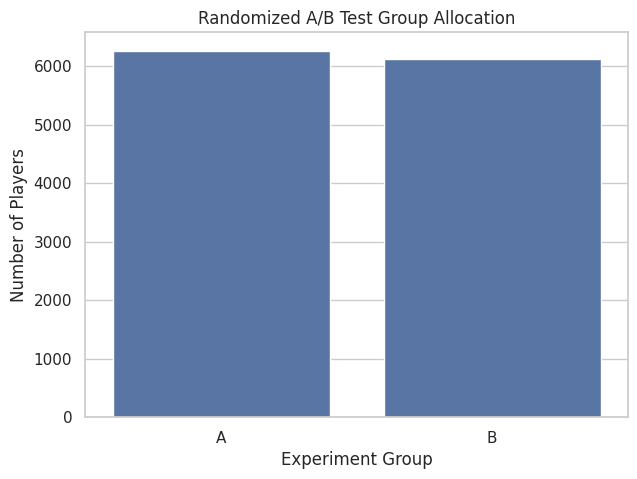

In [37]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=experiment_df,
    x="group"
)

plt.title("Randomized A/B Test Group Allocation")
plt.xlabel("Experiment Group")
plt.ylabel("Number of Players")

plt.show()

#We need to confirm that both groups have reasonably comparable historical player behaviour.

In [38]:
balance_summary = experiment_df.groupby("group").agg(
    player_count=("user_id", "count"),
    avg_hours=("total_hours", "mean"),
    median_hours=("total_hours", "median"),
    avg_purchases=("total_purchases", "mean"),
    median_purchases=("total_purchases", "median")
)

display(balance_summary.round(2))

,player_count,avg_hours,median_hours,avg_purchases,median_purchases
group,,,,,
A,6265,281.65,13.4,10.22,2.0
B,6128,274.28,13.5,10.57,2.0


In [39]:
cluster_distribution = pd.crosstab(
    experiment_df["cluster"],
    experiment_df["group"],
    normalize="columns"
) * 100

display(cluster_distribution.round(2))

group,A,B
cluster,,
0,53.47,52.68
1,31.57,32.10
2,14.96,15.23


In [40]:
baseline_conversion_by_cluster = {
    0: 0.05,
    1: 0.08,
    2: 0.12
}

treatment_uplift_by_cluster = {
    0: 0.02,
    1: 0.02,
    2: 0.02
}

experiment_df["baseline_probability"] = (
    experiment_df["cluster"].map(
        baseline_conversion_by_cluster
    )
)

experiment_df["treatment_uplift"] = (
    experiment_df["cluster"].map(
        treatment_uplift_by_cluster
    )
)

experiment_df["conversion_probability"] = np.where(
    experiment_df["group"] == "B",
    experiment_df["baseline_probability"] +
    experiment_df["treatment_uplift"],
    experiment_df["baseline_probability"]
)

In [42]:
#These outcomes are synthetic. We are not claiming these clicks or purchases occurred on Steam.

experiment_df["click_probability"] = np.where(
    experiment_df["group"] == "B",
    0.16,
    0.12
)

experiment_df["clicked"] = np.random.binomial(
    1,
    experiment_df["click_probability"]
)

experiment_df["converted"] = np.random.binomial(
    1,
    experiment_df["conversion_probability"]
)

display(experiment_df.head())

,user_id,total_interactions,unique_games,total_hours,total_purchases,log_total_hours,cluster,group,treatment,baseline_probability,treatment_uplift,conversion_probability,click_probability,clicked,converted
0,5250,27,21,225.5,21,5.422745,2,A,0,0.12,0.02,0.12,0.12,0,0
1,76767,56,36,1227.0,36,7.113142,2,B,1,0.12,0.02,0.14,0.16,0,0
2,86540,97,82,255.0,82,5.545177,2,B,1,0.12,0.02,0.14,0.16,0,0
3,103360,10,10,0.0,10,0.000000,0,B,1,0.05,0.02,0.07,0.16,1,1
4,144736,9,8,0.1,8,0.095310,0,A,0,0.05,0.02,0.05,0.12,0,0


#Calculate experiment metrics

In [43]:
experiment_results = experiment_df.groupby("group").agg(
    total_players=("user_id", "count"),
    total_clicks=("clicked", "sum"),
    total_conversions=("converted", "sum")
)

experiment_results["CTR"] = (
    experiment_results["total_clicks"] /
    experiment_results["total_players"]
)

experiment_results["conversion_rate"] = (
    experiment_results["total_conversions"] /
    experiment_results["total_players"]
)

display(experiment_results.round(4))

,total_players,total_clicks,total_conversions,CTR,conversion_rate
group,,,,,
A,6265,749,421,0.1196,0.0672
B,6128,992,547,0.1619,0.0893


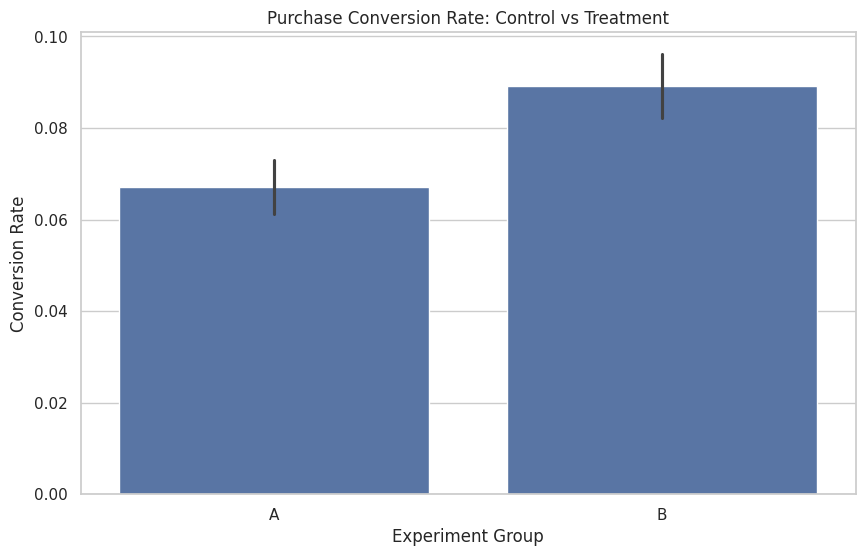

In [44]:
sns.barplot(
    data=experiment_df,
    x="group",
    y="converted"
)

plt.title("Purchase Conversion Rate: Control vs Treatment")
plt.xlabel("Experiment Group")
plt.ylabel("Conversion Rate")

plt.show()

In [45]:
control_rate = experiment_results.loc[
    "A", "conversion_rate"
]

treatment_rate = experiment_results.loc[
    "B", "conversion_rate"
]

absolute_lift = treatment_rate - control_rate

relative_lift = (
    absolute_lift / control_rate
) * 100 if control_rate > 0 else np.nan

print("Control Conversion:", round(control_rate * 100, 2), "%")
print("Treatment Conversion:", round(treatment_rate * 100, 2), "%")

print("Absolute Lift:", round(absolute_lift * 100, 2), "percentage points")
print("Relative Lift:", round(relative_lift, 2), "%")

Control Conversion: 6.72 %
Treatment Conversion: 8.93 %
Absolute Lift: 2.21 percentage points
Relative Lift: 32.83 %


In [46]:
experiment_df.to_csv(
    "simulated_ab_test_data.csv",
    index=False
)

from google.colab import files

files.download("simulated_ab_test_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>